# 05 - Modelling

Predict `compressive_strength` (MPa) from the 7 ingredients and curing age.

1. Setup  2. Model comparison  3. Monotonic constraints  4. Hyperparameter tuning  5. Model selection  6. Held-out test  7. Robustness  8. Physical sanity checks  9. Final fit and save  10. Summary

**Ground rules**
- All validation uses the **age-stratified** folds from `04_DataSplit`, so every model is scored on the same rows.
- Models are compared and tuned on the 5 CV folds of the training set only. The test set is scored **once**, in section 6.
- Every model is a full `Pipeline` that starts from the 8 raw inputs; feature engineering (`ML/features.py`) is its first step.
- Models learn **√strength** and the prediction is squared back, so strength can never be negative (section 3 shows why).

---
## 1. Setup

In [ ]:
import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

BACKEND = Path('..').resolve()
sys.path.insert(0, str(BACKEND))   # makes "ML.features" (and the read-only presets in model_service) importable

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor,
                              VotingRegressor)
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

from ML.features import (INGREDIENTS, MODEL_FEATURES, MONOTONE_DIRECTIONS, RAW_FEATURES, TARGET,
                         ConcreteFeatures, monotone_vector, sqrt_inverse)

warnings.filterwarnings('ignore', message='X does not have valid feature names')
SEED, N_JOBS = 42, 4
MODEL_DIR = Path('models')
MODEL_FILE = 'concrete_strength_model_v2.joblib'   # the app's current model file is left untouched
OLD_MODEL_FILE = 'concrete_strength_model.joblib'
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.3f}'.format)

COLOR, COLOR_2, GREY = '#2a78d6', '#d6762a', '#a3a29c'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e1e0d9', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'font.size': 10,
})

In [ ]:
data = pd.read_csv(Path('data') / 'splits.csv')
train = data[data['split'] == 'train'].reset_index(drop=True)
test = data[data['split'] == 'test'].reset_index(drop=True)

X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]
X_all, y_all = data[RAW_FEATURES], data[TARGET]

FOLDS = sorted(train['fold'].unique())
CV_SPLITS = [(np.flatnonzero(train['fold'] != f), np.flatnonzero(train['fold'] == f)) for f in FOLDS]

print(f'Train: {len(train)} rows / {train.mix_id.nunique()} mixes   Test: {len(test)} rows / {test.mix_id.nunique()} mixes')
for f, (a, v) in zip(FOLDS, CV_SPLITS):
    print(f'  {f}: train {len(a)}, validate {len(v)}')

Train: 804 rows / 375 mixes   Test: 201 rows / 152 mixes
  fold_1: train 643, validate 161
  fold_2: train 643, validate 161
  fold_3: train 643, validate 161
  fold_4: train 643, validate 161
  fold_5: train 644, validate 160


Helpers:
- `make_pipe` builds `[ConcreteFeatures →] [StandardScaler →] model`, where the model learns √strength (`target='sqrt'`) unless `target='raw'`. With `features='raw'` the model sees the 8 raw columns (including raw age), which shows what feature engineering adds.
- `cv_predict` returns out-of-fold predictions on the training set and pooled metrics. Pooled R² over all out-of-fold rows is used, with the spread of the per-fold R² as a stability check.

In [ ]:
def make_pipe(model, features='engineered', scale=False, target='sqrt'):
    steps = [('features', ConcreteFeatures())] if features == 'engineered' else []
    if scale:
        steps.append(('scaler', StandardScaler()))
    if target == 'sqrt':
        model = TransformedTargetRegressor(regressor=model, func=np.sqrt, inverse_func=sqrt_inverse, check_inverse=False)
    steps.append(('model', model))
    return Pipeline(steps)


def metrics(y, p, prefix):
    return {f'{prefix}_R2': r2_score(y, p), f'{prefix}_RMSE': root_mean_squared_error(y, p),
            f'{prefix}_MAE': mean_absolute_error(y, p)}


def cv_predict(pipe, X=X_train, y=y_train, splits=CV_SPLITS):
    oof, fold_r2 = np.zeros(len(y)), []
    for a, v in splits:
        oof[v] = clone(pipe).fit(X.iloc[a], y.iloc[a]).predict(X.iloc[v])
        fold_r2.append(r2_score(y.iloc[v], oof[v]))
    return oof, {**metrics(y, oof, 'CV'), 'CV_fold_R2_std': float(np.std(fold_r2))}

---
## 2. Model comparison

Eight model families with sensible, untuned settings, each on two feature sets:
- **raw**: the 8 inputs as they are
- **engineered**: the 7 ingredients + log(age), water/binder, water/cement, total binder

Ridge, KNN and SVR are scaled; tree models don't need it. All models learn √strength.

In [ ]:
def candidates():
    return {
        'Ridge': (Ridge(alpha=1.0), True),
        'KNN': (KNeighborsRegressor(n_neighbors=5, weights='distance'), True),
        'SVR (RBF)': (SVR(C=50, gamma=0.1, epsilon=0.5), True),
        'Random Forest': (RandomForestRegressor(n_estimators=500, max_features=0.6, random_state=SEED, n_jobs=N_JOBS), False),
        'Extra Trees': (ExtraTreesRegressor(n_estimators=800, max_features=0.8, random_state=SEED, n_jobs=N_JOBS), False),
        'Gradient Boosting': (GradientBoostingRegressor(n_estimators=800, learning_rate=0.03, max_depth=4, subsample=0.7,
                                                        min_samples_leaf=5, random_state=SEED), False),
        'XGBoost': (XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=4, subsample=0.7, colsample_bytree=0.7,
                                 min_child_weight=2, reg_lambda=5, random_state=SEED, n_jobs=N_JOBS), False),
        'LightGBM': (LGBMRegressor(n_estimators=1000, learning_rate=0.03, num_leaves=15, min_child_samples=5, subsample=0.7,
                                   subsample_freq=1, colsample_bytree=0.7, reg_lambda=5, random_state=SEED,
                                   n_jobs=N_JOBS, verbose=-1), False),
    }


rows = []
t0 = time.perf_counter()
for feats in ['raw', 'engineered']:
    for name, (model, scale) in candidates().items():
        pipe = make_pipe(model, feats, scale)
        _, m = cv_predict(pipe)
        fitted = clone(pipe).fit(X_train, y_train)
        rows.append({'model': name, 'features': feats, **m,
                     'train_R2': r2_score(y_train, fitted.predict(X_train))})
comparison = pd.DataFrame(rows)
comparison['overfit_gap'] = comparison['train_R2'] - comparison['CV_R2']
print(f'{len(rows)} configurations in {time.perf_counter() - t0:.0f}s')
comparison.sort_values('CV_RMSE').reset_index(drop=True)

16 configurations in 36s


,model,features,CV_R2,CV_RMSE,CV_MAE,CV_fold_R2_std,train_R2,overfit_gap
0,Gradient Boosting,engineered,0.928,4.400,2.948,0.020,0.986,0.058
1,XGBoost,engineered,0.926,4.451,3.027,0.020,0.984,0.058
2,LightGBM,engineered,0.926,4.460,2.944,0.022,0.989,0.063
3,LightGBM,raw,0.922,4.592,3.039,0.025,0.989,0.067
4,Gradient Boosting,raw,0.921,4.620,3.125,0.026,0.985,0.064
5,XGBoost,raw,0.920,4.647,3.181,0.023,0.982,0.062
6,Extra Trees,engineered,0.908,4.990,3.200,0.022,0.997,0.090
7,Random Forest,engineered,0.904,5.090,3.567,0.025,0.987,0.083
8,Extra Trees,raw,0.896,5.285,3.460,0.029,0.997,0.101
9,Random Forest,raw,0.891,5.414,3.853,0.025,0.985,0.094


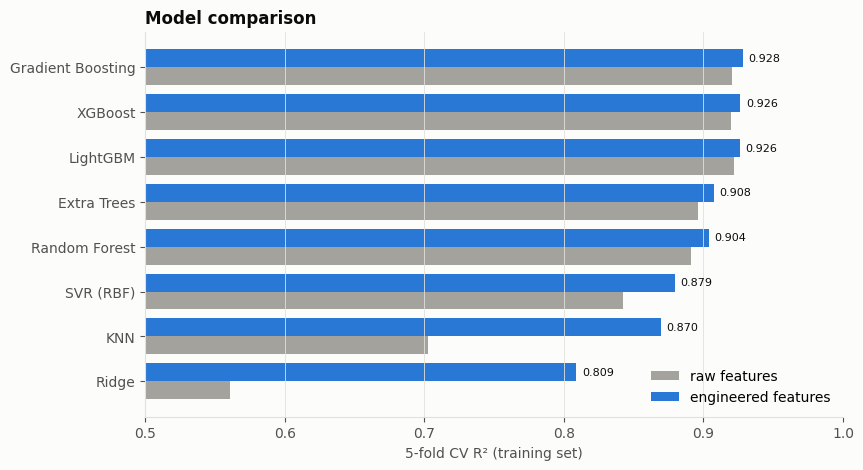

CV R² gain from engineered features: {'Ridge': 0.249, 'KNN': 0.167, 'SVR (RBF)': 0.037, 'Random Forest': 0.013, 'Extra Trees': 0.011, 'Gradient Boosting': 0.007, 'XGBoost': 0.007, 'LightGBM': 0.004}


In [ ]:
pivot = comparison.pivot(index='model', columns='features', values='CV_R2').sort_values('engineered')
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(pivot))
ax.barh(y - 0.2, pivot['raw'], height=0.4, color=GREY, label='raw features')
ax.barh(y + 0.2, pivot['engineered'], height=0.4, color=COLOR, label='engineered features')
for i, (r, e) in enumerate(zip(pivot['raw'], pivot['engineered'])):
    ax.annotate(f'{e:.3f}', (e, i + 0.2), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK)
ax.set_yticks(y, pivot.index)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel('5-fold CV R² (training set)')
ax.set_title('Model comparison', loc='left')
ax.legend(frameon=False, loc='lower right')
ax.grid(axis='y', visible=False)
plt.show()

gain = (pivot['engineered'] - pivot['raw']).sort_values(ascending=False)
print('CV R² gain from engineered features:', gain.round(3).to_dict())

**Reading the comparison**
- The ratio features (especially water/binder) and log(age) help almost every model. Linear models gain the most because log(age) straightens the curing curve.
- The gradient-boosted trees (LightGBM, XGBoost, Gradient Boosting) lead and are close together. LightGBM and XGBoost support monotonic constraints, so they go forward.
- Train R² near 1 for the forests is expected; what matters is CV on unseen mixes.

---
## 3. Monotonic constraints

Unconstrained trees can learn bumps that break physics, e.g. strength that drops between 28 and 56 days, or less strength for more cement (the previous model did both). The app's age curves and sensitivity charts would show these directly.

The boosted models can be told that some features only push strength one way:

| feature | direction |
|---|---|
| log(age) | ↑ strength never falls with curing time |
| cement, total binder | ↑ |
| water, water/binder, water/cement | ↓ |

Only LightGBM and XGBoost are considered here, since they support constraints. The cost in accuracy is measured here.

In [ ]:
CONSTRAINT_SETS = {'none': {}, 'age only': {'log_age': 1}, 'physics': MONOTONE_DIRECTIONS}


def with_constraints(name, model, directions):
    mono = monotone_vector() if directions is MONOTONE_DIRECTIONS else [directions.get(c, 0) for c in MODEL_FEATURES]
    return clone(model).set_params(monotone_constraints=tuple(mono) if name == 'XGBoost' else mono)


base = candidates()
rows = []
for name in ['LightGBM', 'XGBoost']:
    for label, directions in CONSTRAINT_SETS.items():
        _, m = cv_predict(make_pipe(with_constraints(name, base[name][0], directions)))
        rows.append({'model': name, 'constraints': label, **m})
constraint_table = pd.DataFrame(rows).set_index(['model', 'constraints'])
constraint_table[['CV_R2', 'CV_RMSE', 'CV_MAE', 'CV_fold_R2_std']]

CV_R2  CV_RMSE  CV_MAE  CV_fold_R2_std
model    constraints                                        
LightGBM none         0.926    4.453   2.938           0.022
         age only     0.925    4.480   3.046           0.026
         physics      0.926    4.465   3.120           0.023
XGBoost  none         0.926    4.451   3.027           0.020
         age only     0.925    4.497   3.117           0.023
         physics      0.922    4.578   3.197           0.023

The constraints cost only a few thousandths of R² (well inside the fold-to-fold spread), and in return the model can't contradict basic concrete technology. **All models from here on use the physics constraints.**

Note: the constraints act on the model's input columns. Age, water and cement only enter through constrained columns, so strength is *guaranteed* to rise with age and cement and fall with water. (That is why ratios such as SCM fraction or aggregate/binder are not used: they contain cement but have no safe direction, and with them adding cement lowered strength somewhere in about 7 of 10 mixes.)

### 3.1 Why predict √strength?

Constraints stop the curves from bending the wrong way, but they don't stop them from going **below zero**. Mixes that were only ever tested at 28 days (mostly low-cement fly-ash mixes) get their 3-day value by extrapolation, and with a plain target the model predicted down to about −10 MPa for some of them. Learning √strength and squaring the prediction makes negative strength impossible and keeps the constraints intact. Below: the physics-constrained models with both targets, plus the lowest prediction over the age curves (3 → 365 days) of all 428 mixes.

In [ ]:
from model_service import PRESETS, UI_AGES   # read-only import of app constants (presets, curve ages)

mixes = data.drop_duplicates('mix_id')[INGREDIENTS].reset_index(drop=True)
curve_rows = mixes.loc[mixes.index.repeat(len(UI_AGES))].assign(age=np.tile(UI_AGES, len(mixes)))[RAW_FEATURES]

rows = []
for name in ['LightGBM', 'XGBoost']:
    for target in ['raw', 'sqrt']:
        pipe = make_pipe(with_constraints(name, base[name][0], MONOTONE_DIRECTIONS), target=target)
        _, m = cv_predict(pipe)
        curves = clone(pipe).fit(X_train, y_train).predict(curve_rows)
        rows.append({'model': name, 'target': target, **m, 'min_prediction_MPa': curves.min(),
                     'negative_predictions': int((curves < 0).sum())})
pd.DataFrame(rows).set_index(['model', 'target'])[['CV_R2', 'CV_RMSE', 'CV_MAE', 'min_prediction_MPa', 'negative_predictions']]

CV_R2  CV_RMSE  CV_MAE  min_prediction_MPa  negative_predictions
model    target                                                                  
LightGBM raw     0.924    4.513   3.146              -4.288                    11
         sqrt    0.926    4.465   3.120               2.208                     0
XGBoost  raw     0.922    4.594   3.218              -4.574                    19
         sqrt    0.922    4.578   3.197               2.377                     0

---
## 4. Hyperparameter tuning (Optuna)

LightGBM and XGBoost are tuned with Optuna's TPE sampler, minimising **CV RMSE** on the same 5 folds. 30 trials per model; a progress bar shows each trial.

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30
MONO = monotone_vector()


def build(name, p):
    if name == 'LightGBM':
        return LGBMRegressor(**p, subsample_freq=1, monotone_constraints=MONO, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
    return XGBRegressor(**p, monotone_constraints=tuple(MONO), random_state=SEED, n_jobs=N_JOBS)


def suggest(name, t):
    lr = t.suggest_float('learning_rate', 0.01, 0.1, log=True)
    if name == 'LightGBM':
        return dict(n_estimators=t.suggest_int('n_estimators', 300, 1500, step=100), learning_rate=lr,
                    num_leaves=t.suggest_int('num_leaves', 4, 48), min_child_samples=t.suggest_int('min_child_samples', 3, 30),
                    subsample=t.suggest_float('subsample', 0.5, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.4, 1.0),
                    reg_lambda=t.suggest_float('reg_lambda', 1e-3, 30, log=True), reg_alpha=t.suggest_float('reg_alpha', 1e-3, 5, log=True))
    return dict(n_estimators=t.suggest_int('n_estimators', 300, 1500, step=100), learning_rate=lr,
                    max_depth=t.suggest_int('max_depth', 2, 8), min_child_weight=t.suggest_float('min_child_weight', 1, 10),
                    subsample=t.suggest_float('subsample', 0.5, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.4, 1.0),
                    reg_lambda=t.suggest_float('reg_lambda', 1e-2, 30, log=True), reg_alpha=t.suggest_float('reg_alpha', 1e-3, 5, log=True))


def cv_rmse(pipe):
    oof = np.zeros(len(y_train))
    for a, v in CV_SPLITS:
        oof[v] = clone(pipe).fit(X_train.iloc[a], y_train.iloc[a]).predict(X_train.iloc[v])
    return root_mean_squared_error(y_train, oof)


studies, tuned = {}, {}
for name in ['LightGBM', 'XGBoost']:
    t0 = time.perf_counter()
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(lambda t: cv_rmse(make_pipe(build(name, suggest(name, t)))), n_trials=N_TRIALS, show_progress_bar=True)
    studies[name] = study
    tuned[name] = make_pipe(build(name, study.best_params))
    print(f'{name:22s} best CV RMSE {study.best_value:.3f} MPa  ({time.perf_counter() - t0:.0f}s)')
    print('   ', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in study.best_params.items()})

  0%|          | 0/30 [00:00<?, ?it/s]

LightGBM               best CV RMSE 4.333 MPa  (56s)
    {'learning_rate': 0.0253, 'n_estimators': 1200, 'num_leaves': 27, 'min_child_samples': 4, 'subsample': 0.8263, 'colsample_bytree': 0.4123, 'reg_lambda': 0.0334, 'reg_alpha': 0.1043}


  0%|          | 0/30 [00:00<?, ?it/s]

XGBoost                best CV RMSE 4.350 MPa  (87s)
    {'learning_rate': 0.0277, 'n_estimators': 1100, 'max_depth': 7, 'min_child_weight': 6.3736, 'subsample': 0.8769, 'colsample_bytree': 0.5567, 'reg_lambda': 0.0141, 'reg_alpha': 0.0037}


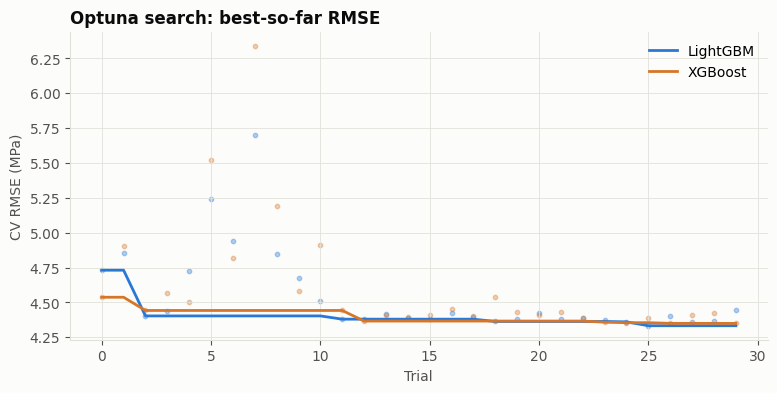

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for (name, s), c in zip(studies.items(), [COLOR, COLOR_2, GREY]):
    vals = [t.value for t in s.trials]
    ax.plot(np.minimum.accumulate(vals), color=c, linewidth=2, label=name)
    ax.scatter(range(len(vals)), vals, color=c, s=10, alpha=0.35)
ax.set_ylim(top=min(7, ax.get_ylim()[1]))
ax.set_xlabel('Trial')
ax.set_ylabel('CV RMSE (MPa)')
ax.set_title('Optuna search: best-so-far RMSE', loc='left')
ax.legend(frameon=False)
plt.show()

---
## 5. Model selection

Candidates: the two tuned models, plus a simple average of both. The **rule, fixed before looking at the test set**: choose the lowest CV RMSE; the averaged ensemble is only chosen if it beats the best single model by at least 0.05 MPa (otherwise the simpler model wins).

In [ ]:
candidates_final = dict(tuned)
# each member already learns sqrt(strength), so the average itself gets no extra transform
candidates_final['Average of tuned'] = make_pipe(VotingRegressor(
    [(n, p.named_steps['model']) for n, p in tuned.items()]), target='raw')

rows, oofs = [], {}
for name, pipe in candidates_final.items():
    oofs[name], m = cv_predict(pipe)
    rows.append({'model': name, **m})
selection = pd.DataFrame(rows).set_index('model').sort_values('CV_RMSE')
display(selection)

singles = selection.drop(index='Average of tuned')
best_single = singles.index[0]
ens_gain = singles.loc[best_single, 'CV_RMSE'] - selection.loc['Average of tuned', 'CV_RMSE']
best_name = 'Average of tuned' if ens_gain >= 0.05 else best_single
best_pipe = candidates_final[best_name]
print(f'Ensemble gain over {best_single}: {ens_gain:+.3f} MPa  ->  selected: {best_name}')

,CV_R2,CV_RMSE,CV_MAE,CV_fold_R2_std
model,,,,
Average of tuned,0.931,4.322,2.996,0.021
LightGBM,0.930,4.333,3.001,0.022
XGBoost,0.930,4.350,3.017,0.021


Ensemble gain over LightGBM: +0.012 MPa  ->  selected: LightGBM


---
## 6. Held-out test set (scored once)

The selected pipeline is fit on the whole training set and scored on the 20% of rows held out in `04_DataSplit`. None of these rows were used for comparison, tuning or selection.

In [ ]:
model = clone(best_pipe).fit(X_train, y_train)
pred_train, pred_test = model.predict(X_train), model.predict(X_test)
test_metrics = {**metrics(y_test, pred_test, 'test'), 'train_R2': r2_score(y_train, pred_train),
                'train_RMSE': root_mean_squared_error(y_train, pred_train)}
print(f'Selected model: {best_name}')
pd.Series({**selection.loc[best_name, ['CV_R2', 'CV_RMSE', 'CV_MAE']].to_dict(), **test_metrics}).to_frame('value')

Selected model: LightGBM


,value
CV_R2,0.930
CV_RMSE,4.333
CV_MAE,3.001
test_R2,0.945
test_RMSE,3.682
test_MAE,2.449
train_R2,0.984
train_RMSE,2.049


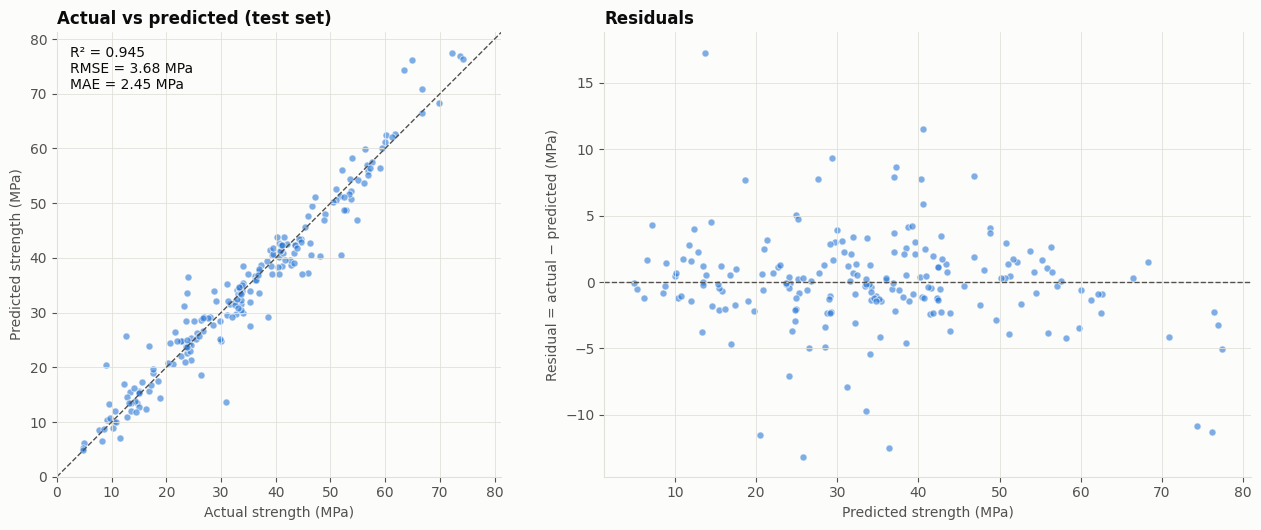

Residual mean -0.01 MPa | within ±5 MPa: 90% | within ±10 MPa: 97%


In [ ]:
resid = y_test - pred_test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={'width_ratios': [1, 1.3]})
lims = [0, max(y_test.max(), pred_test.max()) * 1.05]
ax1.plot(lims, lims, color=INK_2, linestyle='--', linewidth=1)
ax1.scatter(y_test, pred_test, s=26, color=COLOR, alpha=0.6, edgecolor=SURFACE, linewidth=0.8)
ax1.set(xlim=lims, ylim=lims, xlabel='Actual strength (MPa)', ylabel='Predicted strength (MPa)')
ax1.set_aspect('equal')
ax1.set_title('Actual vs predicted (test set)', loc='left')
ax1.text(0.03, 0.97, f"R² = {test_metrics['test_R2']:.3f}\nRMSE = {test_metrics['test_RMSE']:.2f} MPa\n"
         f"MAE = {test_metrics['test_MAE']:.2f} MPa", transform=ax1.transAxes, va='top', color=INK)
ax2.scatter(pred_test, resid, s=26, color=COLOR, alpha=0.6, edgecolor=SURFACE, linewidth=0.8)
ax2.axhline(0, color=INK_2, linestyle='--', linewidth=1)
ax2.set(xlabel='Predicted strength (MPa)', ylabel='Residual = actual − predicted (MPa)')
ax2.set_title('Residuals', loc='left')
fig.tight_layout()
plt.show()
print(f'Residual mean {resid.mean():+.2f} MPa | within ±5 MPa: {(resid.abs() <= 5).mean() * 100:.0f}% '
      f'| within ±10 MPa: {(resid.abs() <= 10).mean() * 100:.0f}%')

### 6.1 Where are the errors?

Errors by curing age and by strength band (test set). `bias` > 0 means the model over-predicts.

In [ ]:
def error_table(groups):
    d = pd.DataFrame({'g': groups, 'y': y_test, 'p': pred_test})
    return d.groupby('g', observed=True).apply(lambda s: pd.Series({
        'rows': len(s), 'RMSE': root_mean_squared_error(s.y, s.p), 'MAE': mean_absolute_error(s.y, s.p),
        'bias': (s.p - s.y).mean()}), include_groups=False)


by_age = error_table(pd.cut(test['age'], [0, 7, 28, 100, 365], labels=['1-7 d', '14-28 d', '56-100 d', '120-365 d']))
by_strength = error_table(pd.cut(y_test, [0, 20, 40, 60, 100], labels=['< 20 MPa', '20-40 MPa', '40-60 MPa', '> 60 MPa']))
display(by_age.round(2), by_strength.round(2))

,rows,RMSE,MAE,bias
g,,,,
1-7 d,51.000,4.880,3.180,-0.920
14-28 d,96.000,3.000,2.030,0.090
56-100 d,42.000,3.860,2.890,0.770
120-365 d,12.000,1.310,1.120,0.670


,rows,RMSE,MAE,bias
g,,,,
< 20 MPa,40.000,3.550,2.230,0.740
20-40 MPa,88.000,3.690,2.350,0.110
40-60 MPa,62.000,3.380,2.470,-1.240
> 60 MPa,11.000,5.340,3.890,3.560


---
## 7. Robustness: how much does the split matter?

A single test set of ~200 rows is noisy, so two extra estimates on all 1005 rows, using the selected configuration (hyperparameters fixed, nothing re-tuned):
- **Repeated age-stratified CV** (3 × 5 folds, random rows): the same kind of split as the test set, averaged over 15 folds. This is the main accuracy figure.
- **Grouped-by-mix CV** (3 × 5 folds, every row of a mix on the same side): how well the model does on a mix design it has **never seen at any age**. Lower, because the model can't lean on other ages of the same mix. Reported for context, so the app's users aren't promised more than the model can do for brand-new designs.

In [ ]:
mix_all = data['mix_id']
age_g = pd.cut(data['age'], [0, 7, 28, 100, 365]).astype(str)
strata_all = age_g + '_' + pd.qcut(y_all, 4).astype(str)
counts = strata_all.value_counts()
strata_all[strata_all.isin(counts[counts < 10].index)] = 'rare'

age_strata = data['age'].replace({1: 3, 120: 100, 360: 365})   # same merging as 04_DataSplit
row_rep, grp_rep = [], []
for r in range(3):
    row_splits = list(StratifiedKFold(5, shuffle=True, random_state=r).split(X_all, age_strata))
    grp_splits = list(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(X_all, strata_all, mix_all))
    row_rep.append(cv_predict(best_pipe, X_all, y_all, row_splits)[1])
    grp_rep.append(cv_predict(best_pipe, X_all, y_all, grp_splits)[1])
row_rep, grp_rep = pd.DataFrame(row_rep), pd.DataFrame(grp_rep)

robust = pd.DataFrame({
    'R2': [row_rep.CV_R2.mean(), grp_rep.CV_R2.mean()], 'R2_std': [row_rep.CV_R2.std(), grp_rep.CV_R2.std()],
    'RMSE': [row_rep.CV_RMSE.mean(), grp_rep.CV_RMSE.mean()], 'MAE': [row_rep.CV_MAE.mean(), grp_rep.CV_MAE.mean()]},
    index=['Age-stratified CV, 3x5 (main)', 'New mix designs: grouped CV, 3x5 (context)'])
robust

,R2,R2_std,RMSE,MAE
"Age-stratified CV, 3x5 (main)",0.934,0.001,4.182,2.781
"New mix designs: grouped CV, 3x5 (context)",0.900,0.001,5.157,3.589


---
## 8. Physical sanity checks

Comparing the new model with the one the app currently serves (`concrete_strength_model.joblib`) on all 428 mix designs in the data:
1. **Age curve**: strength at 3 → 365 days must never fall.
2. **Negative strength**: minimum prediction anywhere on those curves.
3. **Direction of single-ingredient changes** (at 28 days, sweeping one ingredient across its training range with the rest fixed): more cement should not lower strength; more water should not raise it.

These are exactly the views the app shows (age curve and sensitivity tabs). The presets and UI ages come from `model_service.py` (imported read-only in 3.1), so the check uses the same values as the app. For the new model all three are guaranteed by construction; this confirms it.

In [ ]:
old_pipe = joblib.load(MODEL_DIR / OLD_MODEL_FILE)['pipeline']
ranges = {c: (X_all[c].min(), X_all[c].max()) for c in RAW_FEATURES}
TOL = 1e-6


def age_curves(pipe):
    rows = mixes.loc[mixes.index.repeat(len(UI_AGES))].assign(age=np.tile(UI_AGES, len(mixes)))[RAW_FEATURES]
    return pipe.predict(rows).reshape(len(mixes), len(UI_AGES))


def sweep_share(pipe, feature, direction, points=25):
    xs = np.linspace(*ranges[feature], points)
    rows = mixes.loc[mixes.index.repeat(points)].assign(age=28.0)
    rows[feature] = np.tile(xs, len(mixes))
    curves = pipe.predict(rows[RAW_FEATURES]).reshape(len(mixes), points)
    return float((np.diff(curves, axis=1) * direction >= -TOL).all(axis=1).mean() * 100)


checks = {}
for label, pipe in [('current app model', old_pipe), ('new model (train only)', model)]:
    curves = age_curves(pipe)
    checks[label] = {
        'mixes with a falling age curve': int((np.diff(curves, axis=1) < -TOL).any(axis=1).sum()),
        'min predicted strength (MPa)': float(curves.min()),
        'negative predictions': int((curves < 0).sum()),
        '% mixes: more cement never lowers strength': sweep_share(pipe, 'cement', +1),
        '% mixes: more water never raises strength': sweep_share(pipe, 'water', -1),
    }
pd.DataFrame(checks).round(2)

,current app model,new model (train only)
mixes with a falling age curve,193.000,0.000
min predicted strength (MPa),-2.470,1.100
negative predictions,8.000,0.000
% mixes: more cement never lowers strength,0.000,100.000
% mixes: more water never raises strength,0.000,100.000


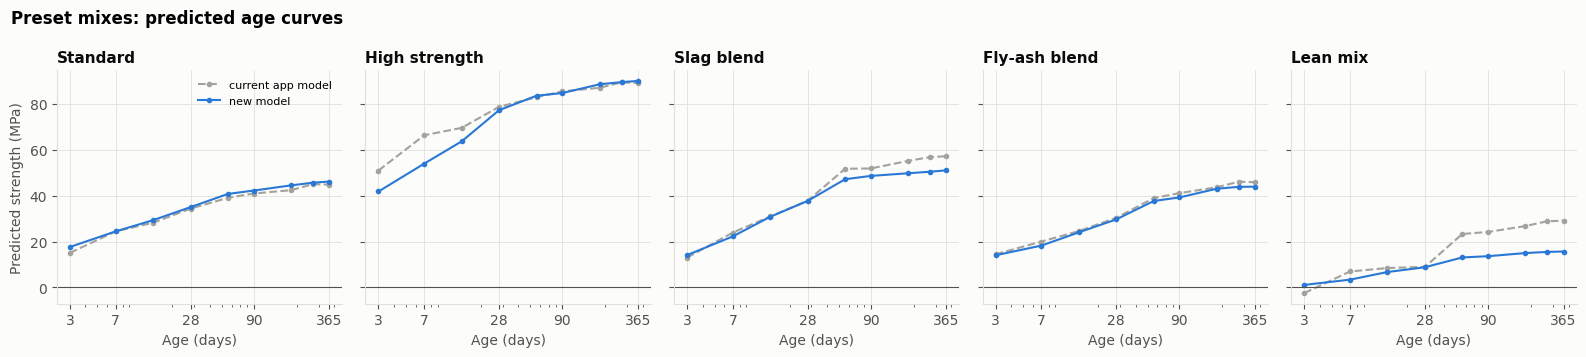

In [ ]:
fig, axes = plt.subplots(1, len(PRESETS), figsize=(16, 3.6), sharey=True)
for ax, (key, p) in zip(axes, PRESETS.items()):
    rows = pd.DataFrame([{**p['mix'], 'age': a} for a in UI_AGES])[RAW_FEATURES]
    ax.plot(UI_AGES, old_pipe.predict(rows), color=GREY, linestyle='--', marker='o', ms=3, label='current app model')
    ax.plot(UI_AGES, model.predict(rows), color=COLOR, marker='o', ms=3, label='new model')
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_xscale('log')
    ax.set_xticks([3, 7, 28, 90, 365], ['3', '7', '28', '90', '365'])
    ax.set_title(p['label'], loc='left', fontsize=11)
    ax.set_xlabel('Age (days)')
axes[0].set_ylabel('Predicted strength (MPa)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Preset mixes: predicted age curves', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

---
## 9. Final fit and save

Evaluation is finished, so the selected configuration is **refit on all 1005 rows** (train + test). This uses 25% more mixes for the model the app will serve; the reported metrics stay the held-out test and CV numbers from sections 5-7.

The bundle has the same keys `model_service.py` reads (`pipeline`, `features`, `feature_ranges`, `metrics` with `test_R2` / `test_RMSE`, `model_name`). `features` are the 8 raw app inputs; the pipeline does the feature engineering itself. It is saved as a **new file**; to use it, the app's `MODEL_FILE` has to point to it.

In [ ]:
final_pipe = clone(best_pipe).fit(X_all, y_all)
final_curves = age_curves(final_pipe)
assert not (np.diff(final_curves, axis=1) < -TOL).any(), 'final model has a falling age curve'
print('Final model: min predicted strength on all age curves =', round(float(final_curves.min()), 2), 'MPa')

bundle = {
    'pipeline': final_pipe,
    'model_name': best_name if best_name != 'Average of tuned' else 'Boosting ensemble',
    'features': RAW_FEATURES,
    'model_features': MODEL_FEATURES,
    'monotone_directions': MONOTONE_DIRECTIONS,
    'target': TARGET,
    'target_unit': 'MPa',
    'target_transform': 'model learns sqrt(strength); prediction = clip(output, 0)**2',
    'feature_ranges': {c: {'min': float(X_all[c].min()), 'max': float(X_all[c].max())} for c in RAW_FEATURES},
    'best_params': {n: s.best_params for n, s in studies.items()} if best_name == 'Average of tuned'
                   else studies[best_name].best_params,
    'metrics': {
        # held-out test rows (never used during selection): what the app shows and uses for its ± band
        **{k: float(v) for k, v in test_metrics.items()},
        'cv_R2': float(selection.loc[best_name, 'CV_R2']), 'cv_RMSE': float(selection.loc[best_name, 'CV_RMSE']),
        'repeated_cv_R2': float(row_rep.CV_R2.mean()), 'repeated_cv_R2_std': float(row_rep.CV_R2.std()),
        'repeated_cv_RMSE': float(row_rep.CV_RMSE.mean()),
        'new_mix_grouped_cv_R2': float(grp_rep.CV_R2.mean()), 'new_mix_grouped_cv_RMSE': float(grp_rep.CV_RMSE.mean()),
    },
    'split': {'method': 'row-level train_test_split stratified by curing age', 'test_fraction': 0.2,
              'random_state': SEED, 'n_train': len(train), 'n_test': len(test)},
    'trained_on': f'all {len(data)} rows after evaluation',
}
out_path = MODEL_DIR / MODEL_FILE
joblib.dump(bundle, out_path)

pd.concat([comparison.assign(stage='2 comparison'),
           constraint_table.reset_index().assign(stage='3 constraints'),
           selection.reset_index().assign(stage='5 tuned')], ignore_index=True
          ).to_csv(MODEL_DIR / 'model_comparison_v2.csv', index=False)
(MODEL_DIR / 'final_metrics_v2.json').write_text(json.dumps(
    {k: v for k, v in bundle.items() if k != 'pipeline'}, indent=2, default=str))
print(f'Saved {out_path} ({out_path.stat().st_size / 1024:.0f} KB), model_comparison_v2.csv, final_metrics_v2.json')

Final model: min predicted strength on all age curves = 0.77 MPa
Saved models\concrete_strength_model_v2.joblib (3108 KB), model_comparison_v2.csv, final_metrics_v2.json


### 9.1 Reload checks

1. Reload here and compare predictions.
2. Load the bundle in a **separate Python process started from `backend/`**, the way the app does, to prove the pickled pipeline finds `ML.features` there. Nothing in `backend/` is modified.

In [ ]:
loaded = joblib.load(out_path)
assert np.allclose(loaded['pipeline'].predict(X_test), final_pipe.predict(X_test))

script = (
    "import joblib, pandas as pd; from model_service import PRESETS; "
    f"b = joblib.load('ML/models/{MODEL_FILE}'); "
    "rows = pd.DataFrame([p['mix'] for p in PRESETS.values()], columns=b['features']).astype(float); "
    "print(b['model_name'], [round(float(v), 1) for v in b['pipeline'].predict(rows)])"
)
res = subprocess.run([sys.executable, '-c', script], cwd=BACKEND, capture_output=True, text=True)
print(res.stdout.strip() or res.stderr)
assert res.returncode == 0, 'bundle failed to load from backend/'

measured = {'standard': 33.1, 'high_strength': 78.8, 'slag_blend': 37.9, 'fly_ash_blend': 32.7, 'lean': 8.5}
print('Measured 28-day strengths of the presets:', measured)

LightGBM [34.3, 77.9, 37.6, 30.6, 8.3]
Measured 28-day strengths of the presets: {'standard': 33.1, 'high_strength': 78.8, 'slag_blend': 37.9, 'fly_ash_blend': 32.7, 'lean': 8.5}


---
## 10. Summary

In [ ]:
m = bundle['metrics']
print(f"""
Selected model           : {bundle['model_name']} with physics monotonic constraints, sqrt target
Features                 : 8 raw inputs -> {len(MODEL_FEATURES)} model features (ML/features.py)

Split stratified by curing age
  Held-out test set      : R2 {m['test_R2']:.3f}   RMSE {m['test_RMSE']:.2f} MPa   MAE {m['test_MAE']:.2f} MPa
  5-fold CV (train)      : R2 {m['cv_R2']:.3f}   RMSE {m['cv_RMSE']:.2f} MPa
  Repeated CV (3x5)      : R2 {m['repeated_cv_R2']:.3f} ± {m['repeated_cv_R2_std']:.3f}   RMSE {m['repeated_cv_RMSE']:.2f} MPa

Completely new mix designs (context)
  Grouped-by-mix CV      : R2 {m['new_mix_grouped_cv_R2']:.3f}   RMSE {m['new_mix_grouped_cv_RMSE']:.2f} MPa

Saved to                 : {out_path}  (refit on all {len(data)} rows)
""")


Selected model           : LightGBM with physics monotonic constraints, sqrt target
Features                 : 8 raw inputs -> 11 model features (ML/features.py)

Split stratified by curing age
  Held-out test set      : R2 0.945   RMSE 3.68 MPa   MAE 2.45 MPa
  5-fold CV (train)      : R2 0.930   RMSE 4.33 MPa
  Repeated CV (3x5)      : R2 0.934 ± 0.001   RMSE 4.18 MPa

Completely new mix designs (context)
  Grouped-by-mix CV      : R2 0.900   RMSE 5.16 MPa

Saved to                 : models\concrete_strength_model_v2.joblib  (refit on all 1005 rows)



**Notes**
- The split is stratified by age at row level, so test rows can be mixes the model saw at other ages. For a mix design that is completely new, expect the lower grouped-by-mix figure.
- The single held-out test set is small (~200 rows); the repeated CV is the steadier number.
- Predictions support preliminary mix design. Laboratory compression testing is still required to confirm a mix.
- Inputs outside `feature_ranges` are extrapolation and should be flagged (the app already does this).